In [ ]:
!pip install transformers datasets -q

In [ ]:
!git clone https://github.com/spMohanty/PlantVillage-Dataset.git

Cloning into 'PlantVillage-Dataset'...
remote: Enumerating objects: 163264, done.
remote: Counting objects: 100% (35/35), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 163264 (delta 16), reused 25 (delta 9), pack-reused 163229 (from 1)
Receiving objects: 100% (163264/163264), 2.00 GiB | 32.51 MiB/s, done.
Resolving deltas: 100% (115/115), done.
Updating files: 100% (182404/182404), done.


In [ ]:
!git clone https://github.com/pratikkayal/PlantDoc-Dataset.git

Cloning into 'PlantDoc-Dataset'...
remote: Enumerating objects: 2670, done.
remote: Counting objects: 100% (35/35), done.
remote: Compressing objects: 100% (13/13), done.
remote: Total 2670 (delta 22), reused 22 (delta 22), pack-reused 2635 (from 1)
Receiving objects: 100% (2670/2670), 932.92 MiB | 32.97 MiB/s, done.
Resolving deltas: 100% (24/24), done.
Updating files: 100% (2581/2581), done.


In [ ]:
!git clone https://github.com/tqwei05/PlantSeg.git

Cloning into 'PlantSeg'...
remote: Enumerating objects: 1250, done.
remote: Counting objects: 100% (124/124), done.
remote: Compressing objects: 100% (44/44), done.
remote: Total 1250 (delta 93), reused 80 (delta 80), pack-reused 1126 (from 1)
Receiving objects: 100% (1250/1250), 53.90 MiB | 30.81 MiB/s, done.
Resolving deltas: 100% (464/464), done.


In [ ]:
!ls PlantVillage-Dataset
!echo "---"
!ls PlantDoc-Dataset
!echo "---"
!ls PlantSeg

CITATION.cff		   generate_lmdb.sh	  logs		    README.md
data_distribution_for_SVM  generate_mapstring.py  plant_village.py  scripts
generate_data_for_SVM.py   leaf_grouping	  raw		    utils
generated_for_paper	   leaf-map.json	  README_HF.md
---
LICENSE.txt  PlantDoc_Examples.png  README.md  test  train
---
coco_annotations  data	 mmseg	    requirements.txt  setup.cfg  tests
configs		  image  README.md  run.sh	      setup.py	 tools


In [ ]:
!cat PlantSeg/README.md | head -50

# PlantSeg: A Large-Scale In-the-wild Dataset for Plant Disease Segmentation
![Alt text](image/seg_samples.png "PlantSeg-logo")



The paper has been accepted for publication in **Scientific Data**.

## Introduction
We established a large-scale plant disease segmentation dataset named PlantSeg. PlantSeg comprises more than 7,774 images of plant diseases from various environments, each annotated with its corresponding segmentation label for diseased parts. To the best of our knowledge, PlantSeg is the largest plant disease segmentation dataset containing in-the-wild images. Our dataset enables researchers to evaluate their models and provides a valid foundation for the development and benchmarking of plant disease segmentation algorithms.

## Curation of our dataset
The curation process of the PlantSeg dataset involves three main steps: image acquisition, data cleaning, and annotation. In the image acquisition stage, images were collected from various internet sources using identified k

In [ ]:
from transformers import AutoModelForImageClassification
from PIL import Image
import torch, glob
from torchvision import transforms

model = AutoModelForImageClassification.from_pretrained("linkanjarad/mobilenet_v2_1.0_224-plant-disease-identification")

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

# grab any one image from PlantVillage's raw folder
sample_paths = glob.glob("PlantVillage-Dataset/raw/**/*.JPG", recursive=True) + \
               glob.glob("PlantVillage-Dataset/raw/**/*.jpg", recursive=True)
print("Found", len(sample_paths), "sample images")
img_path = sample_paths[0]
print("Using:", img_path)

img = Image.open(img_path).convert("RGB")
inputs = transform(img).unsqueeze(0)

with torch.no_grad():
    outputs = model(inputs)

pred = outputs.logits.argmax(-1).item()
print("Predicted class:", model.config.id2label[pred])

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Found 162912 sample images
Using: PlantVillage-Dataset/raw/color/Corn_(maize)___Common_rust_/RS_Rust 2079.JPG
Predicted class: Corn (Maize) with Common Rust


In [ ]:
!ls PlantDoc-Dataset/train
!echo "---"
!find PlantDoc-Dataset/train -maxdepth 1 -type d | wc -l

'Apple leaf'		    'Potato leaf late blight'
'Apple rust leaf'	    'Raspberry leaf'
'Apple Scab Leaf'	    'Soyabean leaf'
'Bell_pepper leaf'	    'Squash Powdery mildew leaf'
'Bell_pepper leaf spot'     'Strawberry leaf'
'Blueberry leaf'	    'Tomato Early blight leaf'
'Cherry leaf'		    'Tomato leaf'
'Corn Gray leaf spot'	    'Tomato leaf bacterial spot'
'Corn leaf blight'	    'Tomato leaf late blight'
'Corn rust leaf'	    'Tomato leaf mosaic virus'
'grape leaf'		    'Tomato leaf yellow virus'
'grape leaf black rot'	    'Tomato mold leaf'
'Peach leaf'		    'Tomato Septoria leaf spot'
'Potato leaf early blight'  'Tomato two spotted spider mites leaf'
---
29


In [ ]:
!pip install zenodo-get -q
!zenodo_get 10.5281/zenodo.17719108 -o PlantSeg_data
!ls PlantSeg_data

INFO: Output directory: /content/PlantSeg_data
INFO: Title: A Large-Scale In-the-wild Dataset for Plant Disease Segmentation
INFO: Total size: 1.1 GB
INFO: Number of files: 1
ERROR: Immediate abort. There might be unfinished files.
^C
plantseg.zip


In [ ]:
import os, random, json

random.seed(42)
base = "PlantVillage-Dataset/raw/color"
classes = os.listdir(base)
splits = {"train": [], "val": [], "test": []}

for c in classes:
    imgs = [os.path.join(base, c, f) for f in os.listdir(os.path.join(base, c))]
    random.shuffle(imgs)
    n = len(imgs)
    train_end = int(0.7 * n)
    val_end = int(0.85 * n)
    splits["train"] += imgs[:train_end]
    splits["val"] += imgs[train_end:val_end]
    splits["test"] += imgs[val_end:]

print({k: len(v) for k, v in splits.items()})

with open("plantvillage_splits.json", "w") as f:
    json.dump(splits, f)

{'train': 37997, 'val': 8146, 'test': 8162}


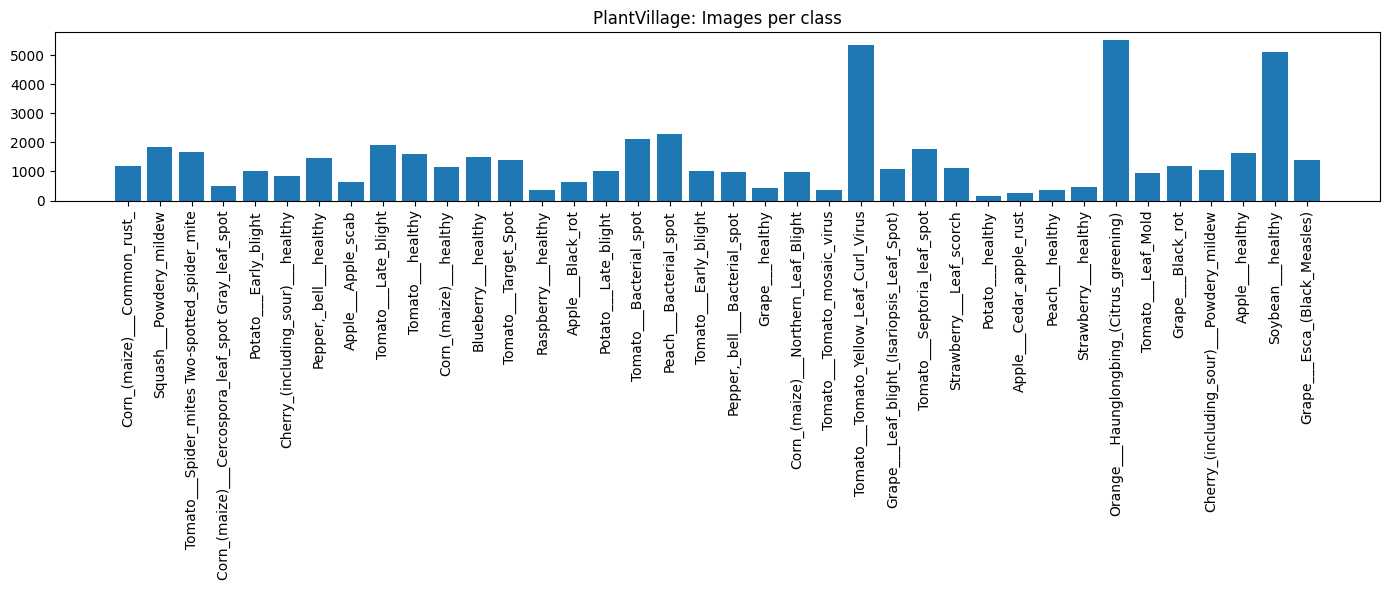

In [ ]:
import matplotlib.pyplot as plt

counts = {c: len(os.listdir(os.path.join(base, c))) for c in classes}
plt.figure(figsize=(14,6))
plt.bar(counts.keys(), counts.values())
plt.xticks(rotation=90)
plt.title("PlantVillage: Images per class")
plt.tight_layout()
plt.savefig("class_distribution.png")
plt.show()

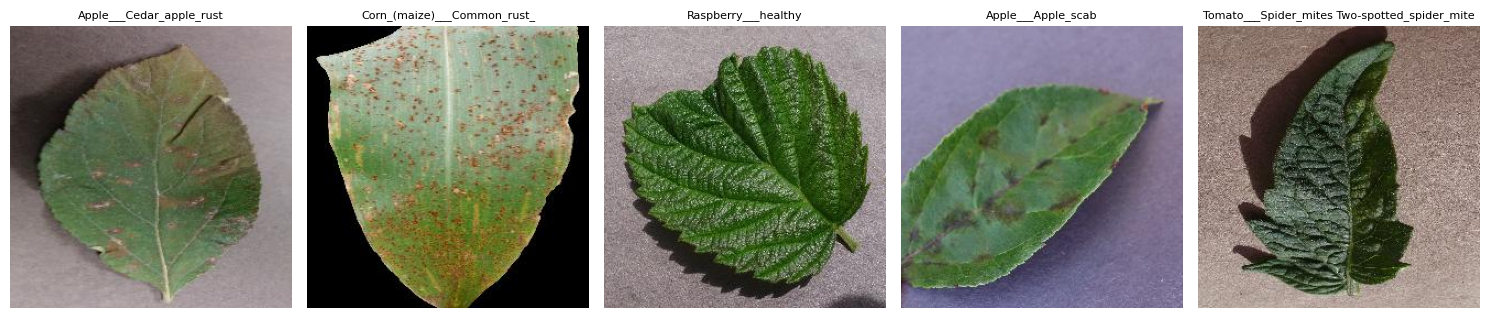

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(1, 5, figsize=(15,4))
sample_classes = random.sample(classes, 5)
for ax, c in zip(axes, sample_classes):
    img_file = os.listdir(os.path.join(base, c))[0]
    img = Image.open(os.path.join(base, c, img_file))
    ax.imshow(img)
    ax.set_title(c, fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
Tesla T4


In [ ]:
!rm -f PlantSeg_data/plantseg.zip

In [ ]:
!ls -lh PlantSeg_data

total 0


In [ ]:
import subprocess
subprocess.Popen(
    "pip install zenodo-get -q && zenodo_get 10.5281/zenodo.17719108 -o PlantSeg_data > plantseg_log.txt 2>&1",
    shell=True
)
print("Started in background — check plantseg_log.txt for progress")

Started in background — check plantseg_log.txt for progress


In [ ]:
import torch, torch.nn as nn, json, os
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from transformers import AutoModelForImageClassification

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cuda


In [ ]:
with open("plantvillage_splits.json") as f:
    splits = json.load(f)

base = "PlantVillage-Dataset/raw/color"
classes = sorted(os.listdir(base))
class_to_idx = {c: i for i, c in enumerate(classes)}

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5]*3, std=[0.5]*3),
])

class LeafDataset(Dataset):
    def __init__(self, paths, class_to_idx, transform):
        self.paths = paths
        self.class_to_idx = class_to_idx
        self.transform = transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, idx):
        path = self.paths[idx]
        label_name = path.split("/")[-2]
        label = self.class_to_idx[label_name]
        img = Image.open(path).convert("RGB")
        return self.transform(img), label

train_ds = LeafDataset(splits["train"], class_to_idx, transform)
val_ds = LeafDataset(splits["val"], class_to_idx, transform)
test_ds = LeafDataset(splits["test"], class_to_idx, transform)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=32, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=32, num_workers=2)

print(len(train_ds), len(val_ds), len(test_ds))

37997 8146 8162


In [ ]:
model = AutoModelForImageClassification.from_pretrained(
    "linkanjarad/mobilenet_v2_1.0_224-plant-disease-identification",
    num_labels=len(classes),
    ignore_mismatched_sizes=True
)
model.to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
criterion = nn.CrossEntropyLoss()

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

In [ ]:
model.train()
for epoch in range(1):
    total_loss = 0
    for i, (imgs, labels) in enumerate(train_loader):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs).logits
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        if i % 50 == 0:
            print(f"Epoch {epoch} Step {i}/{len(train_loader)} Loss {loss.item():.4f}")
    print(f"Epoch {epoch} avg loss: {total_loss/len(train_loader):.4f}")

Epoch 0 Step 0/1188 Loss 0.7398
Epoch 0 Step 50/1188 Loss 0.6013
Epoch 0 Step 100/1188 Loss 0.1032
Epoch 0 Step 150/1188 Loss 0.2162
Epoch 0 Step 200/1188 Loss 0.1224
Epoch 0 Step 250/1188 Loss 0.1472
Epoch 0 Step 300/1188 Loss 0.1076
Epoch 0 Step 350/1188 Loss 0.1522
Epoch 0 Step 400/1188 Loss 0.0871
Epoch 0 Step 450/1188 Loss 0.2460
Epoch 0 Step 500/1188 Loss 0.1849
Epoch 0 Step 550/1188 Loss 0.0951
Epoch 0 Step 600/1188 Loss 0.0958
Epoch 0 Step 650/1188 Loss 0.0718
Epoch 0 Step 700/1188 Loss 0.0703
Epoch 0 Step 750/1188 Loss 0.1012
Epoch 0 Step 800/1188 Loss 0.2689
Epoch 0 Step 850/1188 Loss 0.1478
Epoch 0 Step 900/1188 Loss 0.1816
Epoch 0 Step 950/1188 Loss 0.0839
Epoch 0 Step 1000/1188 Loss 0.1570
Epoch 0 Step 1050/1188 Loss 0.3295
Epoch 0 Step 1100/1188 Loss 0.0600
Epoch 0 Step 1150/1188 Loss 0.1226
Epoch 0 avg loss: 0.1588


In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def evaluate(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            outputs = model(imgs).logits
            preds = outputs.argmax(-1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())
    acc = accuracy_score(all_labels, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average="weighted", zero_division=0)
    return acc, precision, recall, f1, all_preds, all_labels

acc, prec, rec, f1, preds, labels = evaluate(model, test_loader, device)
print(f"PlantVillage (in-domain) — Acc: {acc:.4f}, Precision: {prec:.4f}, Recall: {rec:.4f}, F1: {f1:.4f}")

PlantVillage (in-domain) — Acc: 0.9553, Precision: 0.9636, Recall: 0.9553, F1: 0.9546


In [ ]:
plantdoc_classes = sorted(os.listdir("PlantDoc-Dataset/train"))
print(plantdoc_classes)

['Apple Scab Leaf', 'Apple leaf', 'Apple rust leaf', 'Bell_pepper leaf', 'Bell_pepper leaf spot', 'Blueberry leaf', 'Cherry leaf', 'Corn Gray leaf spot', 'Corn leaf blight', 'Corn rust leaf', 'Peach leaf', 'Potato leaf early blight', 'Potato leaf late blight', 'Raspberry leaf', 'Soyabean leaf', 'Squash Powdery mildew leaf', 'Strawberry leaf', 'Tomato Early blight leaf', 'Tomato Septoria leaf spot', 'Tomato leaf', 'Tomato leaf bacterial spot', 'Tomato leaf late blight', 'Tomato leaf mosaic virus', 'Tomato leaf yellow virus', 'Tomato mold leaf', 'Tomato two spotted spider mites leaf', 'grape leaf', 'grape leaf black rot']


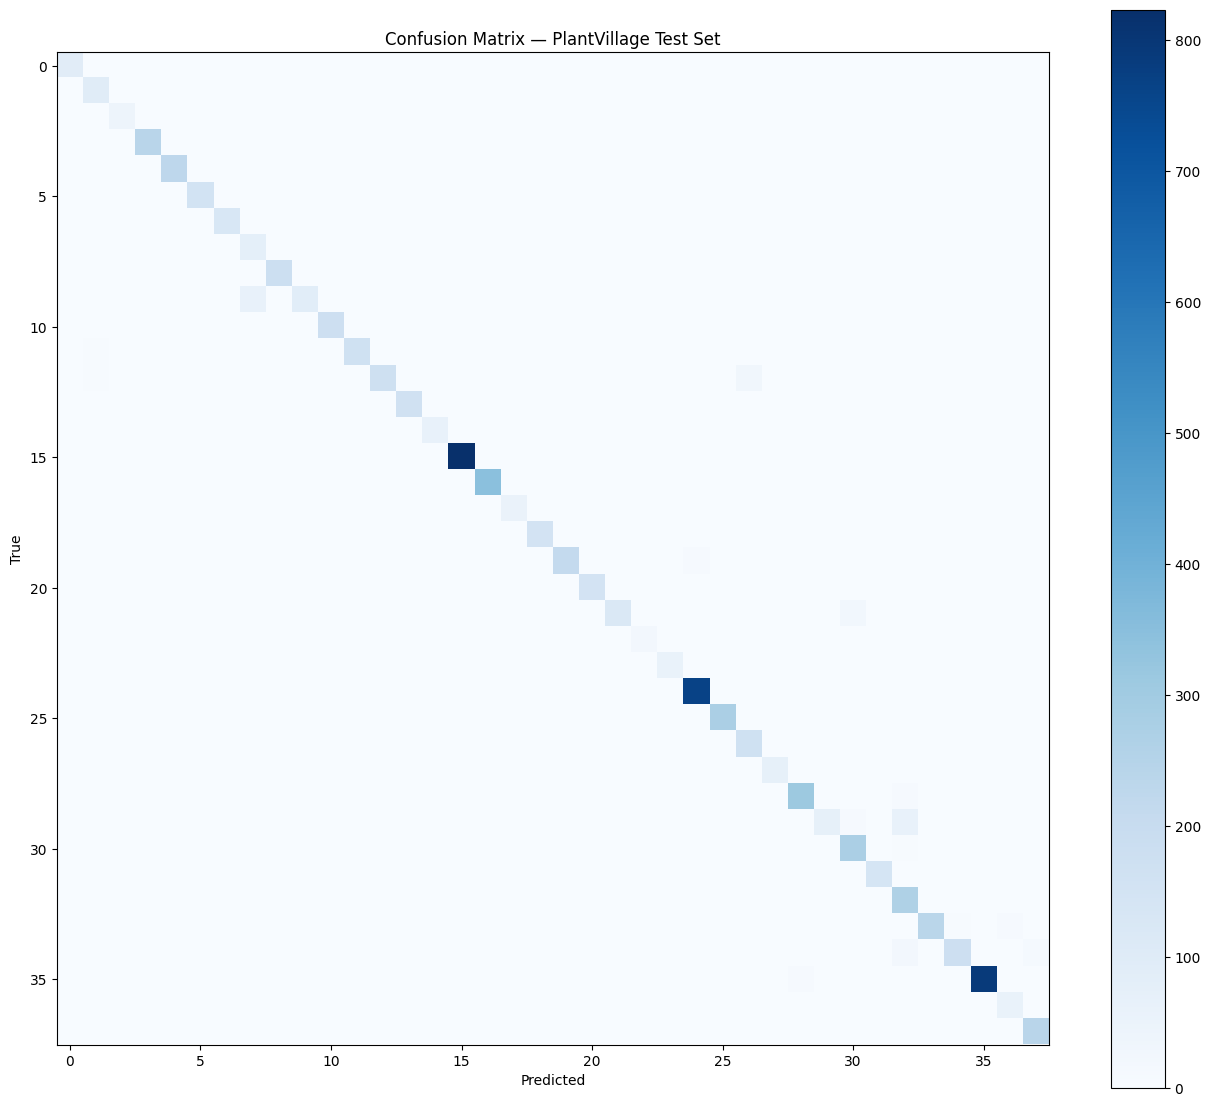

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import numpy as np

cm = confusion_matrix(labels, preds)
plt.figure(figsize=(16,14))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix — PlantVillage Test Set")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.colorbar()
plt.savefig("confusion_matrix_plantvillage.png")
plt.show()

In [ ]:
print(len(plantdoc_classes))
for c in plantdoc_classes:
    print(c)

28
Apple Scab Leaf
Apple leaf
Apple rust leaf
Bell_pepper leaf
Bell_pepper leaf spot
Blueberry leaf
Cherry leaf
Corn Gray leaf spot
Corn leaf blight
Corn rust leaf
Peach leaf
Potato leaf early blight
Potato leaf late blight
Raspberry leaf
Soyabean leaf
Squash Powdery mildew leaf
Strawberry leaf
Tomato Early blight leaf
Tomato Septoria leaf spot
Tomato leaf
Tomato leaf bacterial spot
Tomato leaf late blight
Tomato leaf mosaic virus
Tomato leaf yellow virus
Tomato mold leaf
Tomato two spotted spider mites leaf
grape leaf
grape leaf black rot


In [ ]:
for c in classes:
    print(c)

Apple___Apple_scab
Apple___Black_rot
Apple___Cedar_apple_rust
Apple___healthy
Blueberry___healthy
Cherry_(including_sour)___Powdery_mildew
Cherry_(including_sour)___healthy
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
Corn_(maize)___Common_rust_
Corn_(maize)___Northern_Leaf_Blight
Corn_(maize)___healthy
Grape___Black_rot
Grape___Esca_(Black_Measles)
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
Grape___healthy
Orange___Haunglongbing_(Citrus_greening)
Peach___Bacterial_spot
Peach___healthy
Pepper,_bell___Bacterial_spot
Pepper,_bell___healthy
Potato___Early_blight
Potato___Late_blight
Potato___healthy
Raspberry___healthy
Soybean___healthy
Squash___Powdery_mildew
Strawberry___Leaf_scorch
Strawberry___healthy
Tomato___Bacterial_spot
Tomato___Early_blight
Tomato___Late_blight
Tomato___Leaf_Mold
Tomato___Septoria_leaf_spot
Tomato___Spider_mites Two-spotted_spider_mite
Tomato___Target_Spot
Tomato___Tomato_Yellow_Leaf_Curl_Virus
Tomato___Tomato_mosaic_virus
Tomato___healthy


In [ ]:
plantdoc_to_pv = {
    "Apple Scab Leaf": "Apple___Apple_scab",
    "Apple leaf": "Apple___healthy",
    "Apple rust leaf": "Apple___Cedar_apple_rust",
    "Bell_pepper leaf": "Pepper,_bell___healthy",
    "Bell_pepper leaf spot": "Pepper,_bell___Bacterial_spot",
    "Blueberry leaf": "Blueberry___healthy",
    "Cherry leaf": "Cherry_(including_sour)___healthy",
    "Corn Gray leaf spot": "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn leaf blight": "Corn_(maize)___Northern_Leaf_Blight",
    "Corn rust leaf": "Corn_(maize)___Common_rust_",
    "Peach leaf": "Peach___healthy",
    "Potato leaf early blight": "Potato___Early_blight",
    "Potato leaf late blight": "Potato___Late_blight",
    "Raspberry leaf": "Raspberry___healthy",
    "Soyabean leaf": "Soybean___healthy",
    "Squash Powdery mildew leaf": "Squash___Powdery_mildew",
    "Strawberry leaf": "Strawberry___healthy",
    "Tomato Early blight leaf": "Tomato___Early_blight",
    "Tomato Septoria leaf spot": "Tomato___Septoria_leaf_spot",
    "Tomato leaf": "Tomato___healthy",
    "Tomato leaf bacterial spot": "Tomato___Bacterial_spot",
    "Tomato leaf late blight": "Tomato___Late_blight",
    "Tomato leaf mosaic virus": "Tomato___Tomato_mosaic_virus",
    "Tomato leaf yellow virus": "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato mold leaf": "Tomato___Leaf_Mold",
    "Tomato two spotted spider mites leaf": "Tomato___Spider_mites Two-spotted_spider_mite",
    "grape leaf": "Grape___healthy",
    "grape leaf black rot": "Grape___Black_rot",
}

In [ ]:
class PlantDocDataset(Dataset):
    def __init__(self, root, plantdoc_to_pv, class_to_idx, transform):
        self.samples = []
        self.transform = transform
        for pdoc_class, pv_class in plantdoc_to_pv.items():
            folder = os.path.join(root, pdoc_class)
            if not os.path.isdir(folder):
                continue
            label = class_to_idx[pv_class]
            for fname in os.listdir(folder):
                self.samples.append((os.path.join(folder, fname), label))
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert("RGB")
        return self.transform(img), label

plantdoc_test_ds = PlantDocDataset("PlantDoc-Dataset/test", plantdoc_to_pv, class_to_idx, transform)
plantdoc_loader = DataLoader(plantdoc_test_ds, batch_size=32, num_workers=2)
print("PlantDoc test samples (mapped):", len(plantdoc_test_ds))

PlantDoc test samples (mapped): 236


In [ ]:
acc_pd, prec_pd, rec_pd, f1_pd, preds_pd, labels_pd = evaluate(model, plantdoc_loader, device)
print(f"PlantDoc (zero-shot cross-domain) — Acc: {acc_pd:.4f}, Precision: {prec_pd:.4f}, Recall: {rec_pd:.4f}, F1: {f1_pd:.4f}")

PlantDoc (zero-shot cross-domain) — Acc: 0.2119, Precision: 0.2076, Recall: 0.2119, F1: 0.1624


In [ ]:
print(f"\nDomain gap (accuracy drop): {acc - acc_pd:.4f} ({(acc - acc_pd)*100:.1f} percentage points)")


Domain gap (accuracy drop): 0.7434 (74.3 percentage points)


In [ ]:
torch.save(model.state_dict(), "classifier_finetuned_epoch1.pt")

results_log = {
    "plantvillage_indomain": {"acc": acc, "precision": prec, "recall": rec, "f1": f1},
    "plantdoc_zeroshot": {"acc": acc_pd, "precision": prec_pd, "recall": rec_pd, "f1": f1_pd},
    "domain_gap_pp": (acc - acc_pd) * 100
}
import json
with open("day2_results.json", "w") as f:
    json.dump(results_log, f, indent=2)
print("Saved model and results log")

Saved model and results log


In [ ]:
!tail -5 plantseg_log.txt
!ls -lh PlantSeg_data

INFO: Output directory: /content/PlantSeg_data
INFO: Title: A Large-Scale In-the-wild Dataset for Plant Disease Segmentation
INFO: Total size: 1.1 GB
INFO: Number of files: 1
SUCCESS: All specified files have been processed.
total 1009M
-rw-r--r-- 1 root root 1009M Nov 26 14:23 plantseg.zip


In [ ]:
!unzip -q PlantSeg_data/plantseg.zip -d PlantSeg_data/extracted
!ls PlantSeg_data/extracted

plantseg


In [ ]:
!find PlantSeg_data/extracted/plantseg -maxdepth 3

Streaming output truncated to the last 5000 lines.
PlantSeg_data/extracted/plantseg/images/train/wheat_stripe_rust_Bing_0020.jpg
PlantSeg_data/extracted/plantseg/images/train/blueberry_scorch_Bing_0014.jpg
PlantSeg_data/extracted/plantseg/images/train/tomato_early_blight_google_0003.jpg
PlantSeg_data/extracted/plantseg/images/train/citrus_greening_disease_51.jpg
PlantSeg_data/extracted/plantseg/images/train/peach_brown_rot_Bing_0104.jpg
PlantSeg_data/extracted/plantseg/images/train/wheat_septoria_blotch_Bing_0011.jpg
PlantSeg_data/extracted/plantseg/images/train/citrus_greening_disease_google_0027.jpg
PlantSeg_data/extracted/plantseg/images/train/tobacco_mosaic_virus_37.jpg
PlantSeg_data/extracted/plantseg/images/train/tomato_early_blight_google_0077.jpg
PlantSeg_data/extracted/plantseg/images/train/bean_halo_blight_google_0137.jpg
PlantSeg_data/extracted/plantseg/images/train/tomato_bacterial_leaf_spot_198.jpg
PlantSeg_data/extracted/plantseg/images/train/banana_cordana_leaf_spot_Bing

In [ ]:
!find PlantSeg_data/extracted/plantseg -maxdepth 2 -type d

PlantSeg_data/extracted/plantseg
PlantSeg_data/extracted/plantseg/annotations
PlantSeg_data/extracted/plantseg/annotations/test
PlantSeg_data/extracted/plantseg/annotations/val
PlantSeg_data/extracted/plantseg/annotations/train
PlantSeg_data/extracted/plantseg/images
PlantSeg_data/extracted/plantseg/images/test
PlantSeg_data/extracted/plantseg/images/val
PlantSeg_data/extracted/plantseg/images/train


In [ ]:
import os, glob
import numpy as np
from PIL import Image

root = "PlantSeg_data/extracted/plantseg"

# 1. Counts per split
for s in ["train", "val", "test"]:
    n_img = len(os.listdir(f"{root}/images/{s}"))
    n_ann = len(os.listdir(f"{root}/annotations/{s}"))
    print(s, "images:", n_img, "| annotations:", n_ann)

# 2. Look at filenames side by side
imgs = sorted(os.listdir(f"{root}/images/train"))[:3]
anns = sorted(os.listdir(f"{root}/annotations/train"))[:3]
print(imgs)
print(anns)

# 3. Inspect one mask: size, mode, unique pixel values
m = Image.open(f"{root}/annotations/train/{anns[0]}")
arr = np.array(m)
print("mask mode:", m.mode, "| shape:", arr.shape, "| unique values:", np.unique(arr))

train images: 5367 | annotations: 5367
val images: 846 | annotations: 846
test images: 1561 | annotations: 1561
['apple_black_rot_1.jpg', 'apple_black_rot_11.jpg', 'apple_black_rot_12.jpg']
['apple_black_rot_1.png', 'apple_black_rot_11.png', 'apple_black_rot_12.png']
mask mode: L | shape: (480, 640) | unique values: [0 1]


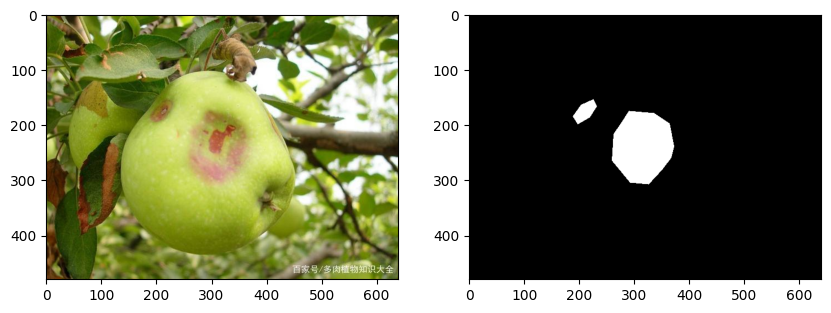

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(Image.open(f"{root}/images/train/{imgs[0].replace('.png','.jpg')}"))
ax[1].imshow(arr, cmap="gray")
plt.show()

In [ ]:
!pip install transformers -q

import torch, torch.nn as nn, os, glob
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import numpy as np
from transformers import SegformerForSemanticSegmentation, SegformerImageProcessor

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cuda


In [ ]:
class PlantSegDataset(Dataset):
    def __init__(self, root, split, img_size=512):
        self.img_dir = f"{root}/images/{split}"
        self.ann_dir = f"{root}/annotations/{split}"
        self.files = sorted(os.listdir(self.img_dir))
        self.img_size = img_size
        self.img_transform = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        fname = self.files[idx]
        stem = os.path.splitext(fname)[0]
        img = Image.open(f"{self.img_dir}/{fname}").convert("RGB")
        mask = Image.open(f"{self.ann_dir}/{stem}.png")

        img_t = self.img_transform(img)
        mask_resized = mask.resize((self.img_size, self.img_size), Image.NEAREST)
        mask_t = torch.from_numpy(np.array(mask_resized)).long()

        return img_t, mask_t

root = "PlantSeg_data/extracted/plantseg"
train_ds = PlantSegDataset(root, "train")
val_ds = PlantSegDataset(root, "val")
test_ds = PlantSegDataset(root, "test")

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=8, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=8, num_workers=2)

print(len(train_ds), len(val_ds), len(test_ds))

5367 846 1561


In [ ]:
model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/segformer-b0-finetuned-ade-512-512",
    num_labels=2,
    ignore_mismatched_sizes=True
)
model.to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=6e-5)

config.json:   0%|          | 0.00/6.88k [00:00<?, ?B/s]

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


model.safetensors: reconstructing file:   0%|          |  0.00B / 15.0MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([2, 256, 1, 1])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


In [ ]:
import torch.nn.functional as F

model.train()
for epoch in range(1):
    total_loss = 0
    for i, (imgs, masks) in enumerate(train_loader):
        imgs, masks = imgs.to(device), masks.to(device)

        outputs = model(pixel_values=imgs)
        logits = outputs.logits  # (B, 2, H/4, W/4)
        logits_upsampled = F.interpolate(logits, size=masks.shape[-2:], mode="bilinear", align_corners=False)

        loss = F.cross_entropy(logits_upsampled, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        if i % 50 == 0:
            print(f"Epoch {epoch} Step {i}/{len(train_loader)} Loss {loss.item():.4f}")
    print(f"Epoch {epoch} avg loss: {total_loss/len(train_loader):.4f}")

AcceleratorError: CUDA error: device-side assert triggered
Search for `cudaErrorAssert' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1


In [ ]:
!pip install transformers -q

In [ ]:
import torch, torch.nn as nn, os, glob
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import numpy as np
from transformers import SegformerForSemanticSegmentation, SegformerImageProcessor

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cuda


In [ ]:
class PlantSegDataset(Dataset):
    def __init__(self, root, split, img_size=512):
        self.img_dir = f"{root}/images/{split}"
        self.ann_dir = f"{root}/annotations/{split}"
        self.files = sorted(os.listdir(self.img_dir))
        self.img_size = img_size
        self.img_transform = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        fname = self.files[idx]
        stem = os.path.splitext(fname)[0]
        img = Image.open(f"{self.img_dir}/{fname}").convert("RGB")
        mask = Image.open(f"{self.ann_dir}/{stem}.png")

        img_t = self.img_transform(img)
        mask_resized = mask.resize((self.img_size, self.img_size), Image.NEAREST)
        mask_t = torch.from_numpy(np.array(mask_resized)).long()

        return img_t, mask_t

root = "PlantSeg_data/extracted/plantseg"
train_ds = PlantSegDataset(root, "train")
val_ds = PlantSegDataset(root, "val")
test_ds = PlantSegDataset(root, "test")

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=8, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=8, num_workers=2)

print(len(train_ds), len(val_ds), len(test_ds))

5367 846 1561


In [ ]:
model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/segformer-b0-finetuned-ade-512-512",
    num_labels=2,
    ignore_mismatched_sizes=True
)
model.to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=6e-5)

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([2, 256, 1, 1])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


In [ ]:
bad_files = []
unique_vals_seen = set()

for split in ["train", "val", "test"]:
    ann_dir = f"{root}/annotations/{split}"
    for fname in os.listdir(ann_dir):
        arr = np.array(Image.open(f"{ann_dir}/{fname}"))
        vals = set(np.unique(arr).tolist())
        unique_vals_seen |= vals
        if not vals.issubset({0, 1}):
            bad_files.append((split, fname, vals))

print("All unique values across all masks:", unique_vals_seen)
print("Number of bad files:", len(bad_files))
print(bad_files[:10])

All unique values across all masks: {0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115}
Number of bad files: 7711
[('train', 'wheat_septoria_blotch_Baidu_0034.png', {0, 109}), ('train', 'cucumber_angular_leaf_spot_78.png', {0, 49}), ('train', 'wheat_powdery_mildew_Bing_0021.png', {0, 108}), ('train', 'wheat_head_scab_Google_0253.png', {0, 105}), ('train', 'banana_cigar_end_rot_Bing_0009.png', {0, 8}), ('train', 'cauliflower_alternaria_leaf_spot_google_0056.png', {0, 33}), ('train', 'tomato_bacterial_leaf_spot_6.png', {0, 97}), ('train', 'zucchini_bacterial_wilt_Google_0343.p

In [ ]:
class PlantSegDataset(Dataset):
    def __init__(self, root, split, img_size=512):
        self.img_dir = f"{root}/images/{split}"
        self.ann_dir = f"{root}/annotations/{split}"
        self.files = sorted(os.listdir(self.img_dir))
        self.img_size = img_size
        self.img_transform = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        fname = self.files[idx]
        stem = os.path.splitext(fname)[0]
        img = Image.open(f"{self.img_dir}/{fname}").convert("RGB")
        mask = Image.open(f"{self.ann_dir}/{stem}.png")

        img_t = self.img_transform(img)
        mask_resized = mask.resize((self.img_size, self.img_size), Image.NEAREST)
        mask_arr = np.array(mask_resized)
        mask_arr = (mask_arr > 0).astype(np.int64)  # binarize: any disease class -> 1 (lesion)
        mask_t = torch.from_numpy(mask_arr).long()

        return img_t, mask_t

root = "PlantSeg_data/extracted/plantseg"
train_ds = PlantSegDataset(root, "train")
val_ds = PlantSegDataset(root, "val")
test_ds = PlantSegDataset(root, "test")

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=8, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=8, num_workers=2)

print(len(train_ds), len(val_ds), len(test_ds))

5367 846 1561


In [ ]:
sample_img, sample_mask = train_ds[0]
print("unique values in binarized mask:", torch.unique(sample_mask))

unique values in binarized mask: tensor([0, 1])


In [ ]:
model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/segformer-b0-finetuned-ade-512-512",
    num_labels=2,
    ignore_mismatched_sizes=True
)
model.to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=6e-5)

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([2, 256, 1, 1])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


In [ ]:
sample_img, sample_mask = train_ds[0]
print("unique values in binarized mask:", torch.unique(sample_mask))

unique values in binarized mask: tensor([0, 1])


In [ ]:
import torch.nn.functional as F

model.train()
for epoch in range(1):
    total_loss = 0
    for i, (imgs, masks) in enumerate(train_loader):
        imgs, masks = imgs.to(device), masks.to(device)

        outputs = model(pixel_values=imgs)
        logits = outputs.logits
        logits_upsampled = F.interpolate(logits, size=masks.shape[-2:], mode="bilinear", align_corners=False)

        loss = F.cross_entropy(logits_upsampled, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        if i % 50 == 0:
            print(f"Epoch {epoch} Step {i}/{len(train_loader)} Loss {loss.item():.4f}")
    print(f"Epoch {epoch} avg loss: {total_loss/len(train_loader):.4f}")

Epoch 0 Step 0/671 Loss 0.7885
Epoch 0 Step 50/671 Loss 0.5815
Epoch 0 Step 100/671 Loss 0.4457
Epoch 0 Step 150/671 Loss 0.3260
Epoch 0 Step 200/671 Loss 0.2811
Epoch 0 Step 250/671 Loss 0.2437
Epoch 0 Step 300/671 Loss 0.3075
Epoch 0 Step 350/671 Loss 0.1743
Epoch 0 Step 400/671 Loss 0.4272
Epoch 0 Step 450/671 Loss 0.2596
Epoch 0 Step 500/671 Loss 0.3345
Epoch 0 Step 550/671 Loss 0.2547
Epoch 0 Step 600/671 Loss 0.2171
Epoch 0 Step 650/671 Loss 0.4836
Epoch 0 avg loss: 0.3411


In [ ]:
def evaluate_segmentation(model, loader, device):
    model.eval()
    total_intersection = 0
    total_union = 0
    total_dice_num = 0
    total_dice_den = 0
    correct_pixels = 0
    total_pixels = 0

    with torch.no_grad():
        for imgs, masks in loader:
            imgs, masks = imgs.to(device), masks.to(device)
            outputs = model(pixel_values=imgs)
            logits = outputs.logits
            logits_up = F.interpolate(logits, size=masks.shape[-2:], mode="bilinear", align_corners=False)
            preds = logits_up.argmax(1)  # (B, H, W)

            # IoU and Dice for lesion class (class 1)
            pred_lesion = (preds == 1)
            true_lesion = (masks == 1)

            intersection = (pred_lesion & true_lesion).sum().item()
            union = (pred_lesion | true_lesion).sum().item()
            total_intersection += intersection
            total_union += union

            total_dice_num += 2 * intersection
            total_dice_den += pred_lesion.sum().item() + true_lesion.sum().item()

            correct_pixels += (preds == masks).sum().item()
            total_pixels += masks.numel()

    iou = total_intersection / (total_union + 1e-8)
    dice = total_dice_num / (total_dice_den + 1e-8)
    pixel_acc = correct_pixels / total_pixels

    return iou, dice, pixel_acc

iou, dice, pixel_acc = evaluate_segmentation(model, test_loader, device)
print(f"Test set — IoU (lesion): {iou:.4f}, Dice: {dice:.4f}, Pixel Accuracy: {pixel_acc:.4f}")

Test set — IoU (lesion): 0.5914, Dice: 0.7433, Pixel Accuracy: 0.8953


In [ ]:
torch.save(model.state_dict(), "segformer_plantseg_epoch1.pt")

seg_results = {
    "train_avg_loss": 0.3411,
    "test_iou_lesion": iou,
    "test_dice": dice,
    "test_pixel_acc": pixel_acc
}
import json
with open("day3_results.json", "w") as f:
    json.dump(seg_results, f, indent=2)
print("Saved segmentation model and results")

Saved segmentation model and results


Predicted severity: 24.42% of image area affected


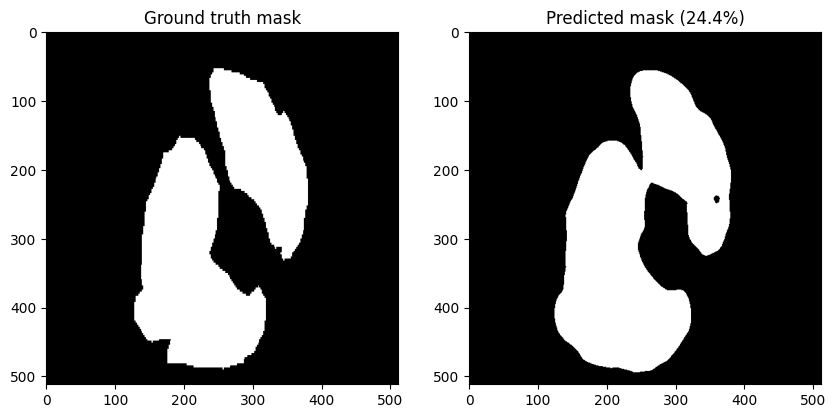

In [ ]:
import matplotlib.pyplot as plt

def compute_severity(model, img_tensor, device):
    model.eval()
    with torch.no_grad():
        img_batch = img_tensor.unsqueeze(0).to(device)
        outputs = model(pixel_values=img_batch)
        logits = outputs.logits
        logits_up = F.interpolate(logits, size=(512, 512), mode="bilinear", align_corners=False)
        pred_mask = logits_up.argmax(1).squeeze(0).cpu().numpy()
    lesion_pixels = (pred_mask == 1).sum()
    total_pixels = pred_mask.size
    severity_pct = (lesion_pixels / total_pixels) * 100
    return severity_pct, pred_mask

sample_img, sample_mask = test_ds[0]
severity_pct, pred_mask = compute_severity(model, sample_img, device)
print(f"Predicted severity: {severity_pct:.2f}% of image area affected")

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(sample_mask, cmap="gray")
ax[0].set_title("Ground truth mask")
ax[1].imshow(pred_mask, cmap="gray")
ax[1].set_title(f"Predicted mask ({severity_pct:.1f}%)")
plt.show()